Total titles: 8807

Content type counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


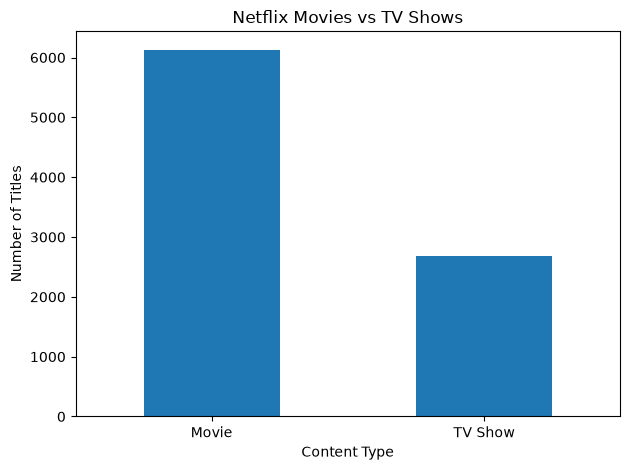


Top 10 genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


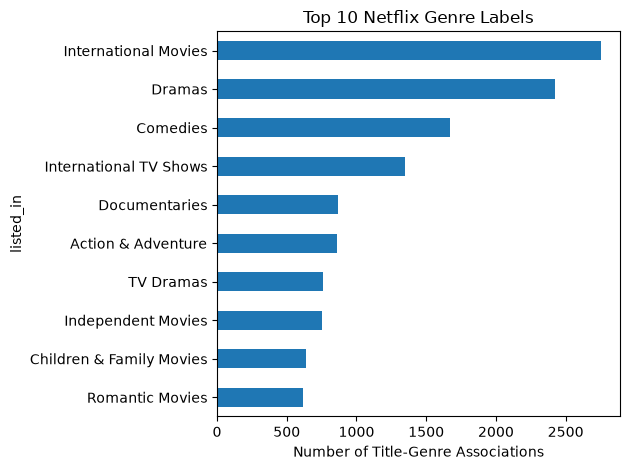


Latest 10 release years by title count:
release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

Titles added by year:
date_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     429
2017    1188
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


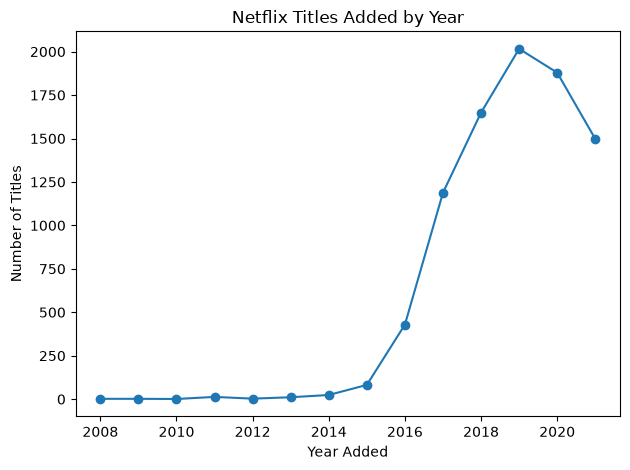

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path.cwd().parent

df = pd.read_csv(
    project_dir / "data" / "processed" / "netflix_clean.csv"
)

report_dir = project_dir / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

print("Total titles:", len(df))
print("\nContent type counts:")
print(df["type"].value_counts(dropna=False))

type_counts = df["type"].value_counts()
type_counts.plot(kind="bar", rot=0)
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig(report_dir / "content_types.png")
plt.show()

genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

print("\nTop 10 genres:")
print(genre_counts.head(10))

genre_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Netflix Genre Labels")
plt.xlabel("Number of Title-Genre Associations")
plt.tight_layout()
plt.savefig(report_dir / "top_genres.png")
plt.show()

release_counts = df["release_year"].value_counts().sort_index()

print("\nLatest 10 release years by title count:")
print(release_counts.tail(10))

added = pd.to_datetime(df["date_added"], errors="coerce")

added_by_year = added.dropna().dt.year.value_counts().sort_index()

print("\nTitles added by year:")
print(added_by_year.tail(15))

added_by_year.plot(kind="line", marker="o")
plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig(report_dir / "titles_added_by_year.png")
plt.show()

In [2]:
from pathlib import Path

report_dir = project_dir / "reports"

type_counts = df["type"].value_counts(dropna=False)
top_genres = genre_counts.head(10)
missing_values = df.isnull().sum()
duplicate_rows = df.duplicated().sum()

report = f"""# Netflix Movies and TV Shows Data Analysis

## 1. Project Overview

This project analyzes Netflix title metadata using Python and Pandas.
The objective is to understand the data, identify quality issues,
analyze content categories, and produce a reliable report.

## 2. Dataset Overview

- Total records: {len(df)}
- Total columns: {len(df.columns)}
- Content types: {type_counts.to_dict()}

## 3. Data Quality

### Missing Values

{missing_values.to_string()}

### Exact Duplicate Rows Remaining

{duplicate_rows}

## 4. Key Findings

### Content Types

{type_counts.to_string()}

### Top Genre Labels

{top_genres.to_string()}

### Titles Added by Year

{added_by_year.tail(15).to_string()}

## 5. Visualizations

- content_types.png
- top_genres.png
- titles_added_by_year.png

## 6. Limitations

This dataset contains content metadata, not Netflix sales,
revenue, or viewership figures. Genre totals count title-genre
associations, so one title may appear in multiple genres.
The findings reflect the downloaded dataset version.

## 7. Verification

The reported values are calculated from the processed dataset.
Review the cleaning notebook and original CSV to validate
the data-cleaning decisions and remaining data-quality issues.
"""

report_path = report_dir / "netflix_analysis_report.md"
report_path.write_text(report, encoding="utf-8")

print("Report created:", report_path)
print("Charts and report saved in:", report_dir)

Report created: c:\ML_Agin\NetflixDataAnalysis\reports\netflix_analysis_report.md
Charts and report saved in: c:\ML_Agin\NetflixDataAnalysis\reports


In [3]:
print("File exists:", report_path.exists())
print("Cleaned dataset exists:",
      (project_dir / "data" / "processed" / "netflix_clean.csv").exists())

for filename in [
    "content_types.png",
    "top_genres.png",
    "titles_added_by_year.png"
]:
    print(filename, (report_dir / filename).exists())

print("Rows in cleaned dataset:", len(df))
print("Content type total:", type_counts.sum())

File exists: True
Cleaned dataset exists: True
content_types.png True
top_genres.png True
titles_added_by_year.png True
Rows in cleaned dataset: 8807
Content type total: 8807


In [4]:
raw_df = pd.read_csv(
    project_dir / "data" / "raw" / "netflix_titles.csv"
)

clean_df = pd.read_csv(
    project_dir / "data" / "processed" / "netflix_clean.csv"
)

print("RAW ROWS:", len(raw_df))
print("CLEANED ROWS:", len(clean_df))

print("\nExact duplicates remaining:", clean_df.duplicated().sum())

print("\nContent type totals:")
print(clean_df["type"].value_counts(dropna=False))

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nDate added range:")
dates = pd.to_datetime(clean_df["date_added"], errors="coerce")
print("Earliest:", dates.min())
print("Latest:", dates.max())

print("\nReport and chart files:")
for name in [
    "netflix_analysis_report.md",
    "content_types.png",
    "top_genres.png",
    "titles_added_by_year.png"
]:
    print(name, (project_dir / "reports" / name).exists())

RAW ROWS: 8807
CLEANED ROWS: 8807

Exact duplicates remaining: 0

Content type totals:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Missing values after cleaning:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Date added range:
Earliest: 2008-01-01 00:00:00
Latest: 2021-09-25 00:00:00

Report and chart files:
netflix_analysis_report.md True
content_types.png True
top_genres.png True
titles_added_by_year.png True
